[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/xiptos/is_notes/blob/main/lstm_text_generation_exercise.ipynb)

# Text generation: writing like Shakespeare

In this exercise you will train a recurrent neural network that writes text **one character at a time**. Like the pixel model of `autoregressive_generator.ipynb`, it is an **autoregressive** model: given the characters written so far, it predicts a probability distribution for the next one,

$$p(c_t \mid c_1, \dots, c_{t-1}),$$

we sample a character from it, append it to the text, and repeat.

### Dataset

We use **Tiny Shakespeare**, a single 1 MB text file with about 40 000 lines from Shakespeare's plays, put together by Andrej Karpathy for his [char-rnn](https://github.com/karpathy/char-rnn) project. It is a good first dataset for text generation because:

* it is one plain text file, with no cleaning to do;
* it has only a few dozen distinct characters, so we need no tokenizer and no word vocabulary;
* a small LSTM learns it in a few minutes, and you can easily tell whether the output "looks like" Shakespeare (character names, line breaks, old English words).

### How this notebook works

* Only the download of the dataset is given. Everything else is for you to write: cells with `...` or `# TODO` are for you to complete.
* Cells marked **Predict first** ask you to write what you *expect* **before** running the code.
* Cells marked **Explain** must be answered in your own words, referring to the **results you obtained**.
* `check(...)` cells test your work. If one fails, fix the cells above it before moving on.
* `lstm.ipynb` shows how to use `nn.Embedding`, `nn.LSTM`, `Dataset` and `DataLoader`. Use a GPU if you can (in Colab: *Runtime → Change runtime type*).

In [1]:
import os
import urllib.request

import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Using", device)

torch.manual_seed(0)


def check(condition, message):
    if not condition:
        raise AssertionError("❌ " + message)
    print("✅", message)

Using cuda


## 1. Dataset

### 1.1 Download and load

The file is downloaded only once. `text` is a single Python string with the whole dataset.

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
FILE = "tinyshakespeare.txt"
if not os.path.exists(FILE):
    urllib.request.urlretrieve(URL, FILE)

with open(FILE, encoding="utf-8") as f:
    text = f.read()

print(f"{len(text):,} characters")
print(text[:500])

1,115,394 characters
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


### 1.2 Explore

Find the distinct characters of `text`, sorted, and print how many there are and what they are.

In [3]:
# TODO: chars = sorted list of the distinct characters of text
chars = sorted(list(set(text)))


In [4]:
check(len(chars) == 65, "the text has 65 distinct characters")

✅ the text has 65 distinct characters


**Explain:** Which kinds of characters appear? Are uppercase and lowercase letters the same character for the model? Why does the newline `\n` matter for the text we want to generate?

**Your answer:**



## 2. From characters to numbers

The network works with integers, not characters. Build:

* `char2idx`: a dictionary from each character to its index in `chars`;
* `idx2char`: the inverse mapping (a list or a dictionary);
* `encode(s)`: a string → a list of integers;
* `decode(ids)`: a list of integers → a string.

Then turn the whole text into a 1-D `torch.long` tensor `data`, and split it **by position**: the first 90% for training (`train_data`) and the last 10% for validation (`valid_data`).

In [5]:
from IPython.utils.py3compat import encode
# TODO: char2idx, idx2char, vocab_size, encode, decode, data, train_data, valid_data
char2idx = {ch: i for i, ch in enumerate(chars)}
idx2char = {i: ch for i, ch in enumerate(chars)}
vocab_size = len(chars)
encode = lambda s: [char2idx[c] for c in s]
decode = lambda ids: "".join([idx2char[i] for i in ids])
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
valid_data = data[n:]

In [6]:
check(vocab_size == 65, "vocab_size is 65")
check(decode(encode("To be, or not to be")) == "To be, or not to be", "decode(encode(s)) gives back s")
check(data.dtype == torch.long and data.shape == (len(text),), "data is a long tensor with one entry per character")
check(len(train_data) + len(valid_data) == len(data), "train and valid together have all the characters")

✅ vocab_size is 65
✅ decode(encode(s)) gives back s
✅ data is a long tensor with one entry per character
✅ train and valid together have all the characters


**Explain:** Why do we split the text by position instead of picking random characters (or random lines) for validation?

**Your answer:**



## 3. Training examples

The model learns to predict **every** next character of a sequence at once. From a chunk of `seq_len + 1` characters we take:

* the input `x`: the first `seq_len` characters;
* the target `y`: the last `seq_len` characters, i.e. the input **shifted by one**.

For example, with `seq_len = 4` and the chunk `"hello"`: `x = "hell"` and `y = "ello"`, so the model must predict `e` after `h`, `l` after `he`, and so on.

Write a `CharDataset(Dataset)` that receives a 1-D tensor and `seq_len` and returns non-overlapping chunks (`__getitem__(i)` starts at `i * seq_len`). Then create `train_loader` (shuffled) and `valid_loader`. Suggested values: `seq_len = 100`, `batch_size = 64`.

In [15]:
seq_len = 100
batch_size = 64

# TODO: CharDataset, train_loader, valid_loader

class CharDataset(Dataset):
  def __init__(self, data, seq_len):
    self.data = data
    self.seq_len = seq_len
  def __len__(self):
    return len(self.data) // self.seq_len
  def __getitem__(self, index):
    start = index * self.seq_len
    end = start + self.seq_len
    x = self.data[start:end]
    y = self.data[start+1:end+1]
    return x, y

train_dataset = CharDataset(train_data, seq_len)
valid_dataset = CharDataset(valid_data, seq_len)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_dataset, batch_size=batch_size, shuffle=False)

In [16]:
x, y = next(iter(train_loader))
check(x.shape == (batch_size, seq_len) and y.shape == (batch_size, seq_len), "a batch has shape (batch_size, seq_len)")
check(bool((x[:, 1:] == y[:, :-1]).all()), "the target is the input shifted by one character")
print(repr(decode(x[0][:60].tolist())))
print(repr(decode(y[0][:60].tolist())))

✅ a batch has shape (batch_size, seq_len)
✅ the target is the input shifted by one character
'e with my repentant tears,\nI will with all expedient duty se'
' with my repentant tears,\nI will with all expedient duty see'


## 4. Model

Write `CharLSTM(nn.Module)` with three layers:

1. [`nn.Embedding`](https://pytorch.org/docs/stable/generated/torch.nn.Embedding.html)`(vocab_size, embedding_dim)`;
2. [`nn.LSTM`](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html)`(embedding_dim, hidden_size, num_layers, batch_first=True)`;
3. `nn.Linear(hidden_size, vocab_size)`, applied to **every** time step.

`forward(x, state=None)` receives a batch of shape `(batch, time)` and returns the logits, of shape `(batch, time, vocab_size)`, **and** the new LSTM state `(h, c)`. Returning the state lets us continue a sequence one character at a time when generating. Suggested values: `embedding_dim = 64`, `hidden_size = 256`, `num_layers = 2`.

In [19]:
# TODO: class CharLSTM(nn.Module)

class CharLSTM(nn.Module):
  def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embedding_dim)
    self.lstm = nn.LSTM(embedding_dim, hidden_size, num_layers, batch_first=True)
    self.linear = nn.Linear(hidden_size, vocab_size)
  def forward(self, x, state=None):
    x = self.embedding(x)
    if state is not None:
      x, state = self.lstm(x, state)
    else:
      x, state = self.lstm(x)
    x = self.linear(x)
    return x, state

model = CharLSTM(vocab_size, 64, 256, 2)


In [21]:
model.to(device)
logits, (h, c) = model(torch.zeros(2, 10, dtype=torch.long, device=device))
check(logits.shape == (2, 10, vocab_size), "logits have shape (batch, time, vocab_size)")

✅ logits have shape (batch, time, vocab_size)


## 5. Generating text

Write `generate(model, start, length, temperature=1.0)`:

1. encode `start` and feed it to the model to get the logits and the state;
2. take the logits of the **last** time step, divide them by `temperature`, and turn them into probabilities with `softmax`;
3. sample the next character with [`torch.multinomial`](https://pytorch.org/docs/stable/generated/torch.multinomial.html);
4. feed **only that character** and the state back to the model, and repeat until you have `length` new characters.

Put the model in evaluation mode and use `torch.no_grad()`. Return `start` followed by the generated text.

In [26]:
def generate(model, start, length, temperature=1.0):
  model.eval()
  with torch.no_grad():
    # Codifica a string inicial e envia para o dispositivo correto
    inputs = torch.tensor(encode(start), device=device).unsqueeze(0)
    logits, state = model(inputs)

    # Obter o primeiro caractere predito
    last_logits = logits[0, -1, :] / temperature
    probs = F.softmax(last_logits, dim=-1)
    next_id = torch.multinomial(probs, num_samples=1)
    generated_ids = [next_id.item()]

    # Loop para gerar os próximos caracteres autorregressivamente
    for _ in range(length - 1):
      # Passa apenas o último caractere gerado e o estado atualizado
      logits, state = model(next_id.unsqueeze(0), state)
      last_logits = logits[0, -1, :] / temperature
      probs = F.softmax(last_logits, dim=-1)
      next_id = torch.multinomial(probs, num_samples=1)
      generated_ids.append(next_id.item())

  return start + decode(generated_ids)

In [27]:
sample = generate(model, "ROMEO:", 50)
check(sample.startswith("ROMEO:") and len(sample) == 56, "generate returns the start plus 50 new characters")

✅ generate returns the start plus 50 new characters


**Predict first:** What will the model write *before* training? Write your guess, then generate 300 characters starting with `"ROMEO:"`.

**Your answer:**



In [28]:
# TODO: generate 300 characters with the untrained model
sample = generate(model, "ROMEO:", 300)
print(sample)

ROMEO:nND.gEWT$SwJGtUucDqi$rZ-P'fKkXcd!kiNHuRz$ngYDI l!3WUW-imntLdu.ILCZhbuH&WtBtzPrE;yMrGj-LVS?S,FahNISskvFCC,QwVaZgPNckB&gLV!jSTNd Xm
rYdFlW
-EbVT:Q.bNIUdsvDt'PdKVVkQyryN.OE&MJvpEp
$jS ohQkMbxGI?sc
lowA:fLsO pbMMVeCTFrA,if?LnqSehWoETL&ZUdF'IcJRXrziZEB3GA,XP3RlJdSecm3elblJ&rX3WJsLvlJ.ojB
R.Zri,IeXmFm?ePw


## 6. Training

[`nn.CrossEntropyLoss`](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) expects logits of shape `(N, vocab_size)` and targets of shape `(N,)`, so flatten the batch and time dimensions (`logits.reshape(-1, vocab_size)`, `y.reshape(-1)`).

**Predict first:** A model that gives the same probability to the 65 characters has a cross-entropy of $\ln 65$. How much is that? Do you expect the trained model to be far below it?

**Your answer:**



Train the model with `Adam` (learning rate `2e-3`) for about 10 epochs. After each epoch:

* compute the average training loss and the validation loss (without gradients);
* print both, and a 200-character sample starting with `"ROMEO:"`.

Keep the losses in the lists `train_losses` and `valid_losses`, and plot them at the end.

In [39]:
epochs = 10
train_losses, valid_losses = [], []

# Otimizador configurado para o novo modelo com Dropout
Adam = torch.optim.Adam(model.parameters(), lr=2e-3)
for epoch in range(epochs):
  # Treinamento
  model.train()
  total_train_loss = 0
  for x, y in train_loader:
    x, y = x.to(device), y.to(device)
    logits, _ = model(x)
    loss = F.cross_entropy(logits.reshape(-1, vocab_size), y.reshape(-1))

    Adam.zero_grad()
    loss.backward()
    Adam.step()
    total_train_loss += loss.item()

  epoch_train_loss = total_train_loss / len(train_loader)
  train_losses.append(epoch_train_loss)

  # Validação
  model.eval()
  total_valid_loss = 0
  with torch.no_grad():
    for x_val, y_val in valid_loader:
      x_val, y_val = x_val.to(device), y_val.to(device)
      logits_val, _ = model(x_val)
      val_loss = F.cross_entropy(logits_val.reshape(-1, vocab_size), y_val.reshape(-1))
      total_valid_loss += val_loss.item()

  epoch_valid_loss = total_valid_loss / len(valid_loader)
  valid_losses.append(epoch_valid_loss)

  print(f"Epoch {epoch+1:02d}/{epochs} | Train Loss: {epoch_train_loss:.4f} | Valid Loss: {epoch_valid_loss:.4f}")
  print(generate(model, "ROMEO:", 200))
  print("-" * 50)

Epoch 01/10 | Train Loss: 2.5235 | Valid Loss: 2.0398
ROMEO:
Say thee or. Ankurt lid hive blaune a pyok, betiess, farhaly ircut the amcorn.

POYS':

LUEy:
Whith, his blean,
O our blands he the sareraqe-rrawffed hemw; to server;
As move potet you dook
The will;
--------------------------------------------------
Epoch 02/10 | Train Loss: 1.9319 | Valid Loss: 1.8393
ROMEO:
Dut reprared would not and besing same;
The poy'd are knengy of shall of manou long.

LETAUTHEUS:
Hith some would be.

MENIUS:
Stry are gefelgen, this cresse, in During fanation, ary?

POLLOND:
What,
--------------------------------------------------
Epoch 03/10 | Train Loss: 1.7555 | Valid Loss: 1.7333
ROMEO:
Sear is it of thy opill that sion.

KING LICARD III:
with, tame these sspets eving bray,
What here as meting parnion the grace: I latt
With givener nover Jurower, and and I god to
wantion as now thee
--------------------------------------------------
Epoch 04/10 | Train Loss: 1.6650 | Valid Loss: 1.6755
ROMEO:
Not

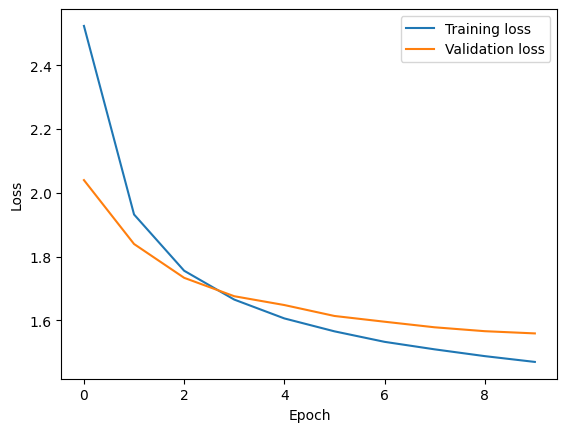

In [40]:
# TODO: plot train_losses and valid_losses
plt.plot(train_losses, label="Training loss")
plt.plot(valid_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

### Mitigação de Overfitting: Nova classe CharLSTM com Dropout

Abaixo está a classe atualizada adicionando regularização por Dropout na camada LSTM e na saída antes da projeção linear.

In [36]:
class CharLSTMWithDropout(nn.Module):
  def __init__(self, vocab_size, embedding_dim, hidden_size, num_layers, dropout_rate=0.3):
    super().__init__()
    self.embedding = nn.Embedding(vocab_size, embedding_dim)
    # Adicionado dropout entre as camadas do LSTM
    self.lstm = nn.LSTM(embedding_dim, hidden_size, num_layers, batch_first=True, dropout=dropout_rate if num_layers > 1 else 0.0)
    self.dropout = nn.Dropout(dropout_rate)
    self.linear = nn.Linear(hidden_size, vocab_size)

  def forward(self, x, state=None):
    x = self.embedding(x)
    if state is not None:
      x, state = self.lstm(x, state)
    else:
      x, state = self.lstm(x)
    x = self.dropout(x) # Aplica dropout nas ativações finais da LSTM
    x = self.linear(x)
    return x, state

# Instancia o novo modelo com dropout
model = CharLSTMWithDropout(vocab_size, 64, 256, 2, dropout_rate=0.4).to(device)
print("Novo modelo com Dropout criado e enviado para o dispositivo:", device)

Novo modelo com Dropout criado e enviado para o dispositivo: cuda


In [41]:
check(len(valid_losses) > 0 and valid_losses[-1] < 2.0, "validation loss below 2.0")

✅ validation loss below 2.0


**Explain:** How did the samples change along the epochs? What did the model learn first (spaces, words, names, line breaks, ...)? Is there any sign of overfitting in your plot?

**Your answer:**



## 7. Temperature

Generate 300 characters with `temperature` 0.2, 0.5, 1.0 and 1.5, always starting with `"ROMEO:"`.

In [42]:
# TODO: one sample for each temperature
sample = generate(model, "ROMEO:", 300, temperature=0.2)
print(sample)

sample = generate(model, "ROMEO:", 300, temperature=0.5)
print(sample)

sample = generate(model, "ROMEO:", 300, temperature=1.0)
print(sample)

ROMEO:
What hast thou shalt strange that shall be the state.

KING RICHARD III:
What we shall be so the state and friends,
That hath a man to see the stranger and here.

Second Citizen:
And then the son that shall be the sentence
That hath made the country to the prince,
The son that hath a prove the fath
ROMEO:
What shall show the state and the world of the son
To stand the commons that would the ground.

LADY ANNE:
The more shall be a gentlering singer
To make her good father grow my lord;
The noble lips, and the shame the conceral hands:
And then when you do with the sight of me not.

KING RICHARD III:

ROMEO:
Every would have approcess; for, mother, you more
Chares and time that first reproomery presence;
Lady but a but his mother is your more
Does my king is not one here, boy,
And do I for us batred no enforce of myself
With men, to thought! Whose name you all:
For woe for sent of these dangerous thron


**Explain:** What does dividing the logits by the temperature do to the probabilities? Describe the text you got with a low and with a high temperature. Which value would you choose, and why?

**Your answer:**



## 8. Going further (optional)

* Train on another text. [Project Gutenberg](https://www.gutenberg.org/) has free books in plain text, for example *Os Lusíadas* in Portuguese. Remember that the vocabulary changes (accented letters).
* Replace the LSTM with an `nn.GRU`, or change `hidden_size` and `num_layers`. How do the number of parameters and the validation loss change?
* Use overlapping chunks (`__getitem__(i)` starting at `i`): you get many more training examples from the same text.

### AI usage declaration

If you used an AI tool (ChatGPT, Copilot, Gemini, Claude, ...) in this exercise, say **which one**, **for which sections**, and **what you asked it**. You may be asked to explain or change any cell of this notebook in class.

**Your answer:**

